In [1]:
## This notebook loads the Bethe surface from Saenz and uses it for cross section calculations

In [2]:
import pylab as plt
import numpy as np
import pandas as pd
import kinematics
import saenzH2

from scipy.integrate import quad
import constants
from scipy.interpolate import LinearNDInterpolator,NearestNDInterpolator
%matplotlib inline


In [3]:
binsK=saenzH2.gosd_simple.K.unique()
binsE=saenzH2.gosd_simple.E.unique()
T=18e3

/var/folders/x8/m88g9m690wb3gf4t7ds85nzw0000gn/T/ipykernel_83111/2287203219.py:5: RuntimeWarning: divide by zero encountered in log
  MinKa2=np.log(kinematics.Ka2Min(E,T,constants.mH*2))


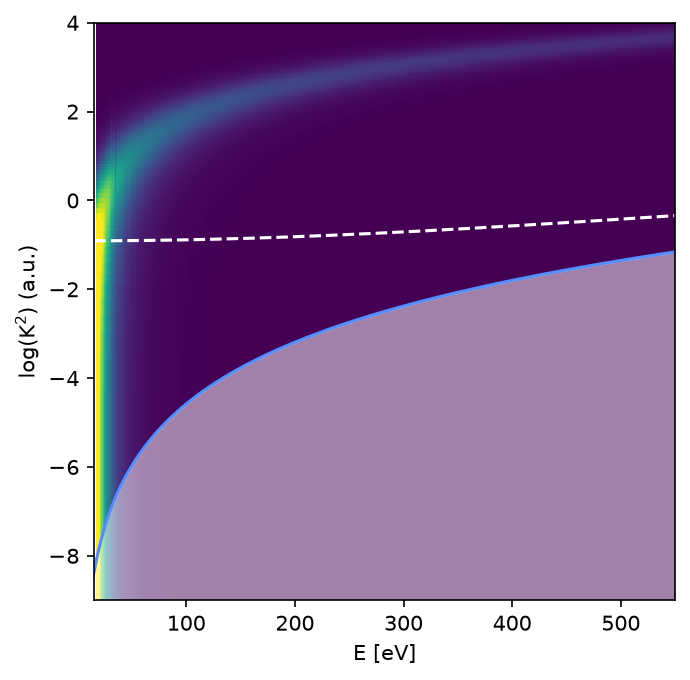

In [4]:

plt.figure(figsize=(5,5),dpi=150)

plt.hist2d(saenzH2.gosd_simple.E*constants.Hartree+1e-6,np.log(saenzH2.gosd_simple.K**2)+1e-6,weights=saenzH2.gosd_simple.GOSD,bins=[binsE*constants.Hartree,np.log(binsK**2)])
E=np.arange(0,600,1)
MinKa2=np.log(kinematics.Ka2Min(E,T,constants.mH*2))
MaxKa2=np.log(kinematics.Ka2Max(E,T,constants.mH*2))
plt.fill_between(E,np.ones_like(E)*-10, MinKa2,color='white',alpha=0.5)
plt.fill_between(E,MaxKa2, np.ones_like(E)*5,color='blue',alpha=0.5)
plt.clim(0,1)
plt.plot(E,MinKa2)
plt.plot(E,MaxKa2)
for Th in [1]:
    CosTh=np.cos(Th*np.pi/180)

    Ka2s=kinematics.GetKa2FromCosTheta(CosTh,T,E,constants.mH*2)

    plt.plot(E,np.log(Ka2s),'--',label=str(Th),color='white')
plt.xlabel("E [eV]")
plt.ylabel("log(K$^2$) (a.u.)")

plt.ylim(-9,4)
plt.xlim(15,550)
#plt.title("Oscillator Strength Density")
plt.savefig("./Plots/H2_OscillatorStrength_Saenz.png",dpi=150)



/var/folders/x8/m88g9m690wb3gf4t7ds85nzw0000gn/T/ipykernel_83111/2656780610.py:6: RuntimeWarning: divide by zero encountered in log
  MinKa2=np.log(kinematics.Ka2Min(E,T,constants.mH*2))


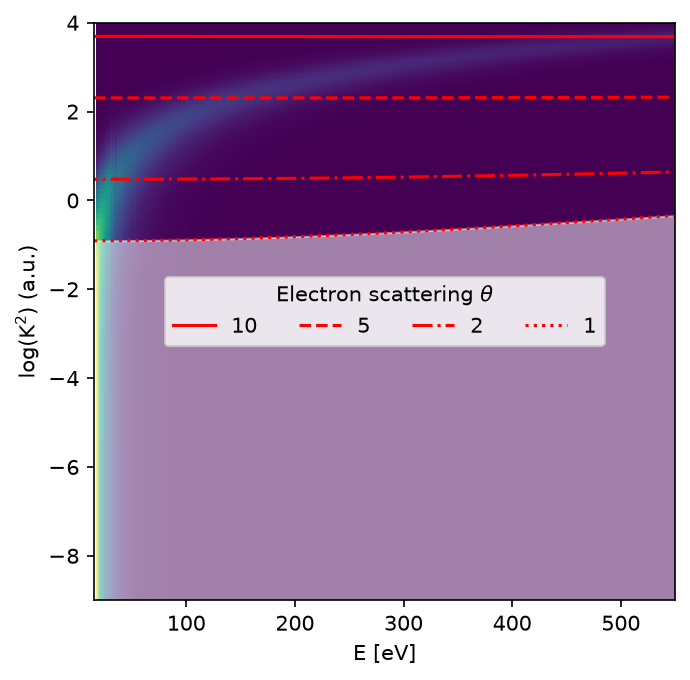

In [5]:

plt.figure(figsize=(5,5),dpi=150)

plt.hist2d(saenzH2.gosd_simple.E*constants.Hartree+1e-6,np.log(saenzH2.gosd_simple.K**2)+1e-6,weights=saenzH2.gosd_simple.GOSD,bins=[binsE*constants.Hartree,np.log(binsK**2)])
E=np.arange(0,600,1)
#plt.colorbar()
MinKa2=np.log(kinematics.Ka2Min(E,T,constants.mH*2))
MaxKa2=np.log(kinematics.Ka2Max(E,T,constants.mH*2))
#plt.fill_between(E,np.ones_like(E)*-10, MinKa2,color='white',alpha=0.5)
#plt.fill_between(E,MaxKa2, np.ones_like(E)*5,color='blue',alpha=0.5)


LineStyles=['-','--','-.',':']
ci=0
for Th in [10,5,2,1]:
    CosTh=np.cos(Th*np.pi/180)

    Ka2s=kinematics.GetKa2FromCosTheta(CosTh,T,E,constants.mH*2)

    plt.plot(E,np.log(Ka2s),LineStyles[ci],label=str(Th),color='red')
    plt.legend(loc='center',title=r'Electron scattering $\theta$',ncol=4)
    ci=ci+1
plt.xlabel("E [eV]")
plt.ylabel("log(K$^2$) (a.u.)")
plt.fill_between(E,np.ones_like(E)*-10, np.log(Ka2s),color='white',alpha=0.5)

plt.ylim(-9,4)
plt.xlim(15,550)
#plt.title("Oscillator Strength Density")
plt.savefig("./Plots/H2_OscillatorStrength_Saenz.png",dpi=150)



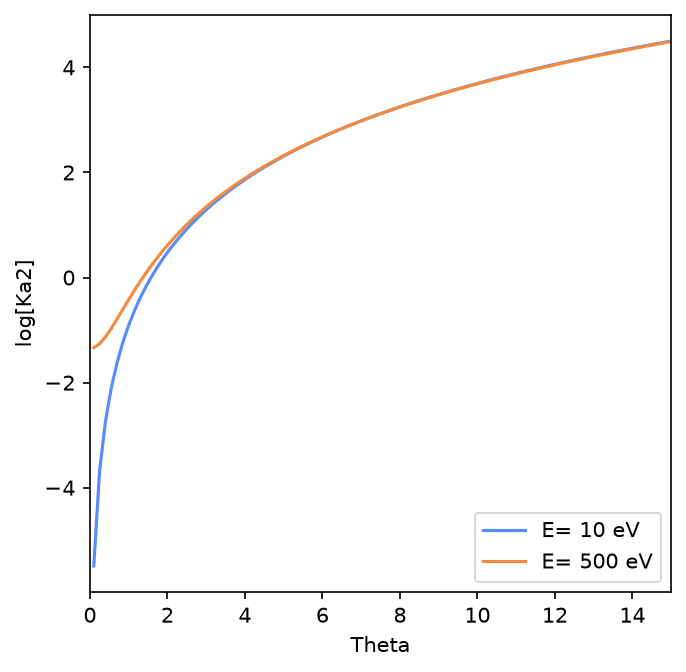

In [6]:
T=18000
plt.figure(figsize=(5,5),dpi=150)
thetas=np.linspace(0.1,15,100)
E=10
M=constants.mH*2
plt.plot(thetas, np.log(kinematics.GetKa2FromCosTheta(np.cos(thetas*np.pi/180),T,E,M)),label='E= 10 eV')
E=500
plt.plot(thetas, np.log(kinematics.GetKa2FromCosTheta(np.cos(thetas*np.pi/180),T,E,M)),label='E= 500 eV')
plt.legend(loc='lower right')
plt.xlim(0,15)
#plt.semilogy()
plt.xlabel("Theta")
plt.ylabel("log[Ka2]")
plt.savefig("./Plots/Kinematics_OscillatorStrength_Saenz.png",dpi=150)


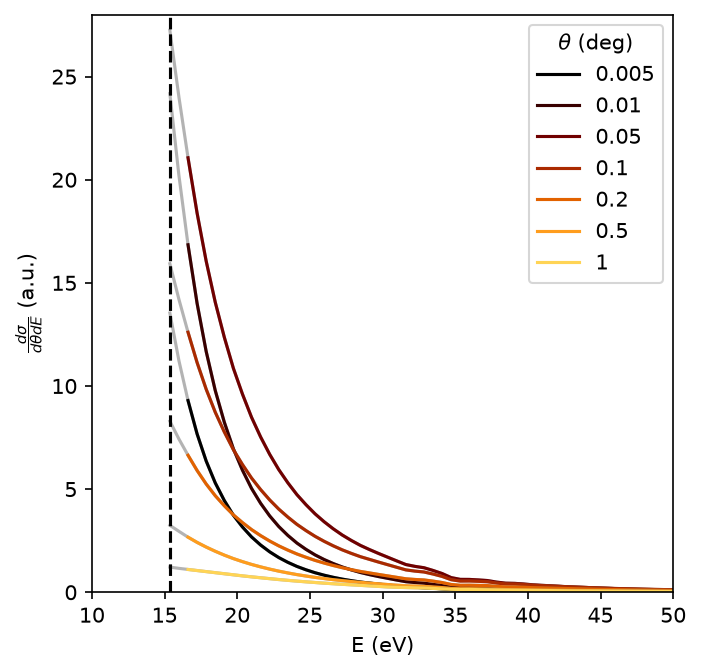

In [7]:

# Ulsh electron energy is 25 keV
T=18000

#Thetas and energies to match Fig 3 of arxiv:2609.12200
thetas=(0.005,0.01,0.05,0.1,0.2, 0.5,1)
E=np.linspace(1,500,800)

#Initial and final electron momenta
p_i = np.sqrt(2*constants.me*T)
p   = np.sqrt(2*constants.me*(T-E))
cm=plt.colormaps.get_cmap('afmhot')
plt.figure(figsize=(5,5),dpi=150)

ci=0
for theta in thetas:

    Costheta    =  np.cos(theta*np.pi/180)

    Ka2         = kinematics.GetKa2FromCosTheta(Costheta,T,E,constants.mH*2)

    OscStrength  =  saenzH2.df_dE_simple(E / constants.Hartree, np.sqrt(Ka2))
    OscStrengthEx = saenzH2.df_dE_ex(E/constants.Hartree,np.sqrt(Ka2))

    dsigdOmdE   = 2/ ((E/constants.Hartree)*Ka2)  * p/p_i  *OscStrength
    dsigdOmdEx   = 2/ ((E/constants.Hartree)*Ka2)  * p/p_i  *OscStrengthEx

    plt.plot(E,2*np.pi*np.sin(theta*np.pi/180)*dsigdOmdEx,color='dimgrey',alpha=0.5)
    plt.plot(E,2*np.pi*np.sin(theta*np.pi/180)*dsigdOmdE,label=theta,color=cm(ci/(len(thetas)+2)))


    ci=ci+1
plt.legend(loc='upper right',title=r'$\theta$ (deg)')

plt.plot([15.4,15.4],[0,30],'--',color='black')
plt.ylabel(r"$\frac{d\sigma}{d\theta dE}$ (a.u.)")
plt.xlabel("E (eV)")
plt.xlim(0,50)
plt.ylim(0,28)
plt.xlim(10,50)
plt.savefig("./Plots/DiffXS_Extrap_Saenz.png",dpi=150)


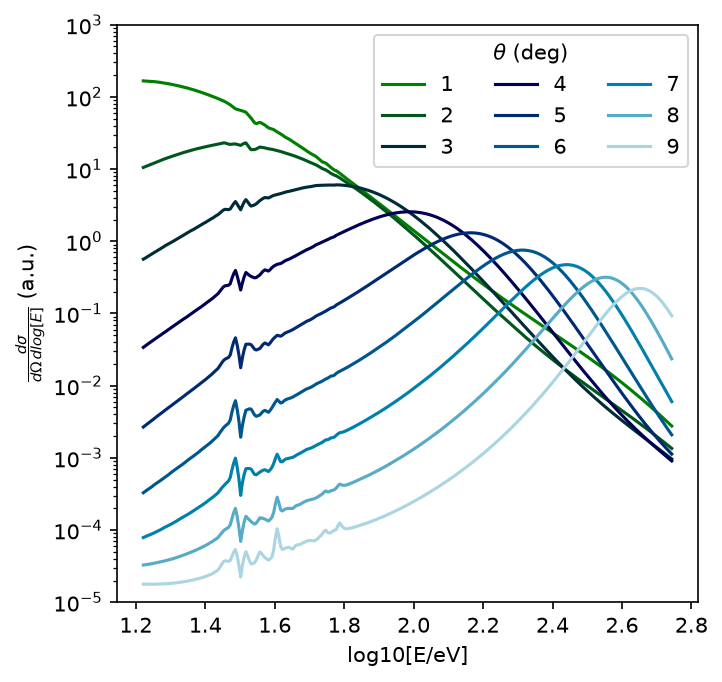

In [8]:
# Ulsh electron energy is 25 keV
T=18000

#Thetas and energies to match Fig 3 of arxiv:2609.12200
thetas=range(1,10)
E=np.logspace(0,4,800)

#Initial and final electron momenta
p_i = np.sqrt(2*constants.me*T)
p   = np.sqrt(2*constants.me*(T-E))
cm=plt.colormaps.get_cmap('ocean')
plt.figure(figsize=(5,5),dpi=150)

ci=0
for theta in thetas:

    Costheta    =  np.cos(theta*np.pi/180)

    Ka2         = kinematics.GetKa2FromCosTheta(Costheta,T,E,constants.mH*2)

    OscStrength = saenzH2.df_dE_simple(E / constants.Hartree, np.sqrt(Ka2))

    dsigdOmdE   = 2/ ((E/constants.Hartree)*Ka2)  * p/p_i  *OscStrength

    plt.plot(np.log10(E),E*dsigdOmdE,label=theta,color=cm(ci/(len(thetas))))
    ci=ci+1
plt.legend(loc='upper right',title=r'$\theta$ (deg)',ncol=3)

plt.ylabel(r"$\frac{d\sigma}{d\Omega \,d log[E]}$ (a.u.)")
plt.xlabel("log10[E/eV]")

plt.ylim(1e-5,1e3)
plt.semilogy()
plt.savefig("./Plots/DiffXS_Saenz.png",dpi=150)


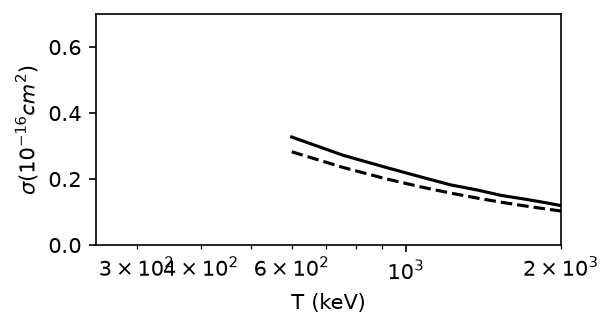

In [18]:

# This constructs a combination interpolator that provides a linear interp inside the
#  support points, but a nearest-neighbor-interp outside them
df_dEovR_ln_in_simple  =LinearNDInterpolator(saenzH2.Points_simple,saenzH2.gosd_simple.GOSD/constants.Hartree*constants.R)
df_dEovR_ln_out_simple =NearestNDInterpolator(saenzH2.Points_simple,saenzH2.gosd_simple.GOSD/constants.Hartree*constants.R)

def ComboInterp_simple(x,y):
    result = df_dEovR_ln_in_simple(x,y)
    mask = np.isnan(result)
    result[mask] = df_dEovR_ln_out_simple(x,y)[mask]
    return result

df_dEovR_ln_in_ex=LinearNDInterpolator(saenzH2.Points_ex,saenzH2.gosd_ex.GOSD/constants.Hartree*constants.R)
df_dEovR_ln_out_ex=NearestNDInterpolator(saenzH2.Points_ex,saenzH2.gosd_ex.GOSD/constants.Hartree*constants.R)


def ComboInterp_ex(x,y):
    result = df_dEovR_ln_in_ex(x,y)
    mask = np.isnan(result)
    result[mask] = df_dEovR_ln_out_ex(x,y)[mask]
    return result


Ts=np.linspace(600,2000,10)
sigs=[]
for T in Ts:
    sigs.append(saenzH2.sig(T,ComboInterp_ex,lnEovRMin=np.log(15.4/constants.R)))

sigsNoEx=[]
for T in Ts:
    sigsNoEx.append(saenzH2.sig(T,ComboInterp_simple))

plt.figure(figsize=(4,2),dpi=150)
plt.plot(Ts,np.array(sigs)*1e20,'-',color='black')
plt.plot(Ts,np.array(sigsNoEx)*1e20,'--',color='black')
#plt.ylim(3e-23,3e-21)
plt.xlim(0,20)
plt.xlim(250,2000)
plt.ylim(0,0.7)
#plt.ylim(1e-23,1e-20)
plt.semilogx()
plt.xlabel("T (keV)")
plt.ylabel(r"$\sigma (10^{-16} cm^2)$")
plt.savefig("Plots/Ionization_CrossSection_H2_Saenz.png",dpi=150,bbox_inches='tight')


In [ ]:
plt.figure(figsize=(5,5),dpi=150)

# This constructs a combination interpolator that provides a linear interp inside the
#  support points, but a nearest-neighbor-interp outside them
df_dEovR_ln_in_simple  =LinearNDInterpolator(saenzH2.Points_simple,saenzH2.gosd_simple.GOSD/constants.Hartree*constants.R)
df_dEovR_ln_out_simple =NearestNDInterpolator(saenzH2.Points_simple,saenzH2.gosd_simple.GOSD/constants.Hartree*constants.R)

def ComboInterp_simple(x,y):
    result = df_dEovR_ln_in_simple(x,y)
    mask = np.isnan(result)
    result[mask] = df_dEovR_ln_out_simple(x,y)[mask]
    return result

df_dEovR_ln_in_ex=LinearNDInterpolator(saenzH2.Points_ex,saenzH2.gosd_ex.GOSD/constants.Hartree*constants.R)
df_dEovR_ln_out_ex=NearestNDInterpolator(saenzH2.Points_ex,saenzH2.gosd_ex.GOSD/constants.Hartree*constants.R)


def ComboInterp_ex(x,y):
    result = df_dEovR_ln_in_ex(x,y)
    mask = np.isnan(result)
    result[mask] = df_dEovR_ln_out_ex(x,y)[mask]
    return result


Ts=np.linspace(600,20000,50)
sigs=[]
for T in Ts:
    sigs.append(saenzH2.sig(T,ComboInterp_ex))

sigsNoEx=[]
for T in Ts:
    sigsNoEx.append(saenzH2.sig(T,ComboInterp_simple))

plt.plot(Ts/1000,np.array(sigs),'-',color='black')
plt.plot(Ts/1000,np.array(sigsNoEx),'--',color='black')
#plt.ylim(3e-23,3e-21)
#plt.xlim(0,20)
plt.ylim(3e-23,3e-21)
plt.xlim(1,20)
plt.legend(loc='upper right',title='Inelastic')
plt.loglog()
plt.ylim(1e-23,1e-20)
plt.xlabel("T (keV)")
plt.ylabel(r"$\sigma (m^2)$")
#plt.savefig("Plots/Ionization_CrossSection_H2_Saenz.png",dpi=150,bbox_inches='tight')
